# Collections recovery — is "+11% MoM" real?
**Reproducible analysis notebook.** Every number is computed from the SQL golden layer (`data/db/collections.sqlite`) by the tested
functions in `src/analysis.py`; this notebook shows the reasoning and the evidence in the order a reviewer would ask for it.
Run `make all` first (or `python -m src.run_pipeline`).

**Classification used throughout:** *Fact* = arithmetic identity/ count reproducible from data · *Strong evidence* = large, robust, survives multiple-testing & sensitivity checks ·
*Correlation* = association without causal design · *Hypothesis* = plausible but not testable with this data.

In [1]:
import os, sys, pickle, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
from src import analysis as A
from src.config import REPORTS_DIR
R = pickle.load(open(REPORTS_DIR / ".results.pkl", "rb")) if (REPORTS_DIR / ".results.pkl").exists() else A.run_all()
CR = 1e7
print("loaded results:", len(R), "objects")

loaded results: 29 objects


## 1. What does the data actually cover?
The brief promises ~12 months. Check coverage before anything else.

In [2]:
con = A.con()
cov = pd.read_sql("""select 'payments' t, min(event_ts_ist) mn, max(event_ts_ist) mx, count(*) n from fact_payment
union all select 'calls', min(event_ts_ist), max(event_ts_ist), count(*) from fact_call
union all select 'targeting', min(target_date), max(target_date), count(*) from fact_targeting
union all select 'accounts opened', min(opened_at), max(opened_at), count(*) from dim_account""", con)
display(cov)
print("-> events cover 1 Jan to 8 Aug 2026 (~7.3 months). August has 8 days: excluded from MoM comparisons. No accounts opened in the window.")

-> events cover 1 Jan to 8 Aug 2026 (~7.3 months). August has 8 days: excluded from MoM comparisons. No accounts opened in the window.


,t,mn,mx,n
0,payments,2026-01-01 00:14:40,2026-08-08 23:50:23,25000
1,calls,2025-12-29 08:22:37,2026-08-12 12:38:19,90000
2,targeting,2026-01-01,2026-08-08,45000
3,accounts opened,2024-01-01 00:02:27,2025-11-30 23:52:36,30000


## 2. Raw → Rejected/Corrected → Golden
`raw = golden + rejected/superseded` holds for every table (asserted in tests).

In [3]:
display(pd.read_sql("select tbl, raw_rows, rejected_rows, clean_rows as golden_rows from recon_row_counts", con))
display(pd.read_sql("select issue_id, area, issue, rows_affected, base_rows from dq_issue_log", con))

,tbl,raw_rows,rejected_rows,golden_rows
0,payments,25500,500,25000
1,calls,91350,1350,90000
2,borrowers,30600,19585,11015
3,agents,30000,29000,1000
4,whatsapp_events,60600,600,60000
5,accounts,30000,0,30000
6,call_attempts,120000,0,120000
7,call_dispositions,35000,0,35000
8,sms_events,45000,0,45000
9,field_visits,25000,0,25000


,issue_id,area,issue,rows_affected,base_rows
0,DQ-01,payments,Duplicate payment_id rows (ingestion retries),500,25500
1,DQ-02,payments,"Rows sharing a payment_reference with a DIFFERENT payment (reference collision, NOT duplicate)",7218,25000
2,DQ-03,payments,Missing payment_reference,368,25000
3,DQ-04,payments,Non-settled payments (FAILED/PENDING/REVERSED) that a raw sum would count,7466,25000
4,DQ-05,payments,SUCCESS payments on current (dpd=0) accounts,1587,17534
5,DQ-06,payments,Payment amount exceeds account outstanding (overpayment),1703,15947
6,DQ-07,calls,Duplicate call_id rows,1350,91350
7,DQ-08,calls,Calls with missing agent_id (after merge),1759,90000
8,DQ-09,calls,Calls outside observation window (late/future/early),52,90000
9,DQ-10,calls,Non-ANSWERED calls with duration>0 (status/duration conflict),72035,90000


## 3. Reproduce the claim — which definition gives +11%?
The dataset contains no "reported" metric table, so we replay plausible definitions. Percent change ≠ percentage-point change: ratios (contact rate, recovery rate) are reported in **pp**, money in **%**.

In [4]:
display(R["claim"])
cal = R["calendar"]
print(f"Feb→Mar golden total: {cal['total_mom']*100:+.2f}%   = calendar days {cal['calendar_days_effect']*100:+.2f}%  ×  per-day {cal['per_day_mom']*100:+.2f}%")
print("identity check (1+cal)(1+perday)-1 =", f"{cal['check_product']*100:+.2f}%")
print("per-day bootstrap CI95:", [f"{x*100:+.1f}%" for x in R['per_day_test']['ci95']], " permutation p =", round(R['per_day_test']['perm_p'], 3))

Feb→Mar golden total: +10.47%   = calendar days +10.71%  ×  per-day -0.22%
identity check (1+cal)(1+perday)-1 = +10.47%
per-day bootstrap CI95: ['-6.7%', '+6.7%']  permutation p = 0.948


,Jan→Feb %,Feb→Mar %,Mar→Apr %,Apr→May %,May→Jun %,Jun→Jul %,max |MoM| %
definition,,,,,,,
"A. Raw payment rows, all statuses, duplicates included (₹)",-9.566,12.231,-5.826,3.354,-4.550,5.923,12.231
"B. Raw SUCCESS rows, duplicates included (₹)",-8.913,10.992,-7.662,4.832,-4.450,6.465,10.992
"C. SUCCESS, de-duplicated (₹)",-9.126,11.032,-7.291,5.203,-4.717,6.654,11.032
"D. GOLDEN net recovery (settled, dedup, delinquent accounts) (₹)",-7.970,10.470,-7.930,6.218,-4.016,7.007,10.470
E. GOLDEN net recovery per observed day (₹/day),1.891,-0.221,-4.861,2.792,-0.816,3.555,4.861


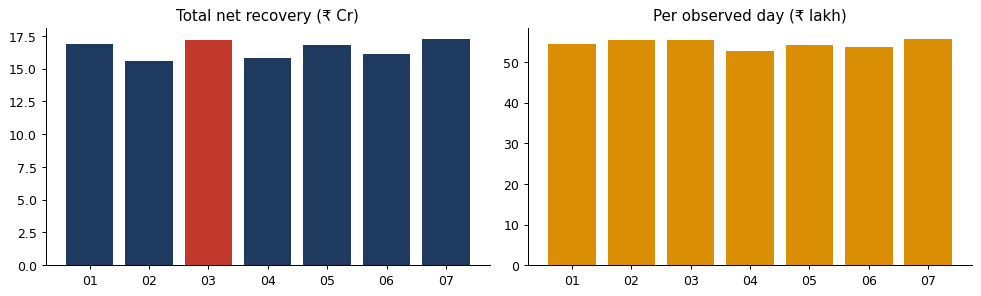

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4)); m = R["monthly"].loc[A.FULL_MONTHS]
ax[0].bar(m.index.str[5:], m.net_inr / CR, color=["#c0392b" if x == "2026-03" else "#1f3a5f" for x in m.index]); ax[0].set_title("Total net recovery (₹ Cr)")
ax[1].bar(m.index.str[5:], m.net_inr_per_day / 1e5, color="#d98e04"); ax[1].set_title("Per observed day (₹ lakh)")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Conclusion 1 (Fact):** raw SETTLED payment rows reproduce ≈ +11% for Feb→Mar; the golden total gives +10.5%; per observed day it is ≈ 0%. The claim is a 28-vs-31-day artefact plus definitional looseness.

### Impact of each cleaning rule on the Feb→Mar headline

In [6]:
display(R["stepwise"]); display(R["waterfall"])

,Feb→Mar %,Feb ₹,Mar ₹
step,,,
"1. Raw, all rows/statuses",12.231,"245,183,619.260","275,173,004.700"
2. + remove duplicate payment_id,12.347,"239,508,700.220","269,081,795.340"
3. + settled (SUCCESS) only,11.032,"170,142,453.760","188,912,374.020"
4. + delinquent accounts only (GOLDEN total),10.470,"155,469,677.080","171,747,190.640"
5. GOLDEN per observed day,-0.221,"5,552,488.467","5,540,231.956"


,step,step_name,delta_inr,running_inr,rows_affected
0,1,"Raw payments, all statuses, incl. duplicates","1,917,258,617.150","1,917,258,617.150",25500
1,2,less: duplicate payment_id rows,"-38,366,344.260","1,878,892,272.890",500
2,3,less: FAILED / PENDING / REVERSED (not settled),"-563,308,308.250","1,315,583,964.640",7466
3,4,less: outside observation window,0.000,"1,315,583,964.640",0
4,5,less: payments on current (dpd=0) accounts - not recovery,"-117,461,931.080","1,198,122,033.560",1587
5,6,= Golden net recovery (is_recovery=1),0.000,"1,198,122,033.560",15947


## 4. Forensics (A–G)
### A. Duplicate payments — and why a repeated `payment_reference` is NOT a duplicate

In [7]:
a = R["A"]; display(a["by_month"]); display(a["dup_kinds"])
print("reference collisions (different account/amount):", a["ref_collisions"], "| same ref+account+amount under distinct ids:", a["same_ref_acct_amount_distinct_ids"])

reference collisions (different account/amount): {'rows_sharing_ref': 7218, 'refs': 3407} | same ref+account+amount under distinct ids: 0


,raw_success,dedup_success,inflation_inr,inflation_pct
report_month,,,,
2026-01,"191,133,284.420","187,229,127.590","3,904,156.830",2.085
2026-02,"174,097,287.960","170,142,453.760","3,954,834.200",2.324
2026-03,"193,233,384.290","188,912,374.020","4,321,010.270",2.287
2026-04,"178,427,017.050","175,138,043.410","3,288,973.640",1.878
2026-05,"187,048,144.340","184,250,278.500","2,797,865.840",1.519
2026-06,"178,724,493.460","175,559,726.970","3,164,766.490",1.803
2026-07,"190,278,846.880","187,242,265.080","3,036,581.800",1.622


,reason,n
0,DUPLICATE_PAYMENT_ID_REFERENCE_MISSING_VARIANT,14
1,EXACT_DUPLICATE_PAYMENT_ID,486


### B. Attribution-window bias — is a payment "caused" by the last touch?
Placebo: keep each payment's account but draw its date at random. If real payments follow touches no more often than placebo payments, attribution is coincidence.

In [8]:
display(R["B_window"]); display(R["B_rules"]["credit"])
print("voice credits whose campaign window excludes the call (%):", round(R["B_rules"]["voice_credit_campaign_window_invalid_pct"], 1))

voice credits whose campaign window excludes the call (%): 81.2


,attributed_pct_of_payments,attributed_inr,last_touch_VOICE_pct,last_touch_WHATSAPP_pct,last_touch_SMS_pct,last_touch_FIELD_pct,placebo_attributed_pct_mean,placebo_sd,excess_over_chance_pp,z
window_days,,,,,,,,,,
1,1.837,"22,144,736.980",0.251,0.765,0.489,0.332,1.906,0.089,-0.069,-0.772
3,5.336,"63,628,466.860",0.734,2.132,1.405,1.066,5.504,0.235,-0.167,-0.712
7,11.946,"143,723,664.550",1.706,4.521,3.267,2.452,12.287,0.290,-0.341,-1.176
14,22.838,"278,338,005.190",3.167,8.698,6.221,4.753,22.672,0.391,0.166,0.425
30,41.331,"496,256,046.140",5.688,15.815,11.400,8.428,40.838,0.358,0.493,1.378


,last_touch_inr,first_touch_inr,swing_pct
FIELD,"28,752,741.190","28,937,866.340",0.644
SMS,"39,144,873.740","38,380,608.550",-1.952
VOICE,"21,455,727.080","20,986,561.250",-2.187
WHATSAPP,"54,370,322.540","55,418,628.410",1.928


### C. Timezones

In [9]:
c = R["C"]
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in c.items() if k != "payment_tz_sensitivity"})
display(c["payment_tz_sensitivity"])

{'calls': 89948, 'pct_hour_changed': np.float64(66.61), 'pct_month_changed': np.float64(0.34), 'pct_outside_8_19_ist': np.float64(54.2), 'pct_outside_8_19_naive': np.float64(54.28), 'tz_mix': {'Asia/Kolkata': 33.4, 'Asia/Dubai': 33.3, 'UTC': 33.3}}


,Feb→Mar total %,Feb→Mar per-day %,payments changing month vs baseline
assumption,,,
baseline: timestamps are IST,10.470,-0.221,0
timestamps are UTC (shift +5:30 to IST),10.701,-0.012,126
timestamps are in account timezone,10.914,0.180,57


### D. Vendor / disposition-code mapping

In [10]:
d = R["D"]; display(d["code_by_version"]); display(d["vendor_map"])
print("version×month χ² p:", round(d["disp_version_month_chi2_p"], 3), "| vendor mix p:", round(d["vendor_mix_chi2_p"], 3),
      "| PTP rate canonical vs legacy-code-only:", round(d["ptp_rate_canonical_pct"], 1), round(d["ptp_rate_legacy_code_only_pct"], 1))

version×month χ² p: 0.493 | vendor mix p: 0.374 | PTP rate canonical vs legacy-code-only: 29.0 14.4


disposition_version,legacy,v1,v2
disposition_code_raw,,,
CALLBACK,1313,1289,1270
DISPUTE,1298,1254,1274
NO_CONTACT,1370,1335,1305
PAID,1251,1248,1319
PROMISE_TO_PAY,1332,1309,1285
PTP,1296,1285,1323
PTP_BROKEN,1274,1313,1313
REFUSED,1236,1301,1261
WRONG_NUMBER,1356,1286,1304


,vendor_name,n_vendor_ids,ids
0,Airtel,5,"VND0000001,VND0000008,VND0000010,VND0000011,VND0000012"
1,Exotel,2,"VND0000002,VND0000009"
2,Knowlarity,3,"VND0000006,VND0000013,VND0000014"
3,TataTele,2,"VND0000007,VND0000015"
4,Twilio,3,"VND0000003,VND0000004,VND0000005"


### E. Agent identity   ·   F. Portfolio mix   ·   G. Denominator

In [11]:
print("E agents:", R["E"])
print("F mix:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in R["F"].items() if k != "avg_outstanding_worked"})
display(R["G"]["table"].round(2))
print({k: v for k, v in R["G"].items() if k != "table"})

E agents: {'agent_ids': 1000, 'snapshot_rows': 30000, 'distinct_names': 10, 'distinct_employee_codes': 1099, 'mean_employee_codes_per_agent_id': 29.604, 'mean_agent_ids_per_employee_code': 26.937215650591448, 'components_if_merged_on_employee_code': 1, 'median_joined_at_spread_days': 661.0, 'overdispersion_contact_rate': {'chi2': 985.2993397771766, 'dof': 999, 'p': 0.6152348995988499}, 'calls_per_agent': 81.242}
F mix: {'opened_range': {'mn': '2024-01-01 00:02:27', 'mx': '2025-11-30 23:52:36'}, 'mix_homogeneity_p': {'dpd_bucket': np.float64(0.9690722292796833), 'loan_type': np.float64(0.9660670080513614), 'risk_segment': np.float64(0.9982196540110438), 'state': np.float64(0.999983890085891)}, 'shift_share_paid_rate_feb_mar': {'rate_p0': 0.07295821316806773, 'rate_p1': 0.08106231557021351, 'total_change': 0.008104102402145777, 'mix_effect': -9.074614072864554e-06, 'rate_effect': 0.008113177016218633}}
{'payments_on_asof_closed': {'n': 3524.0, 'inr': 265845540.76}, 'share_of_recovery_on_

,elig_n,elig_out,net_inr,recovery_rate_fixed_pct,recovery_rate_asof_eligible_pct,rep_recovery_rate_mismatched_denominator_pct,mismatch_cum_change_pct,eligible_base_vs_jan_pct
report_month,,,,,,,,
2026-01,27315,"9,540,816,713.990","168,933,014.870",1.770,1.770,1.770,0.000,0.000
2026-02,24434,"8,532,894,088.200","155,469,677.080",1.630,1.620,1.820,2.900,-10.560
2026-03,22455,"7,833,970,896.870","171,747,190.640",1.800,1.790,2.190,23.820,-17.890
2026-04,20808,"7,251,190,740.460","158,128,022.160",1.660,1.670,2.180,23.160,-24.000
2026-05,19539,"6,808,405,559.810","167,960,571.450",1.760,1.780,2.470,39.330,-28.640
2026-06,18565,"6,472,562,260.280","161,216,016.850",1.690,1.660,2.490,40.670,-32.160
2026-07,17886,"6,246,498,579.670","172,512,972.720",1.810,1.770,2.760,55.980,-34.530


## 5. Independent metric definitions (golden) vs naive
See `docs/metric_definitions.md` for numerator / denominator / eligibility / window of each metric.

In [12]:
cols = ["net_inr", "net_inr_per_day", "recovery_rate_fixed_pct", "recovery_per_account_base", "recovery_per_worked_account", "contact_rate_call_pct", "rep_contact_rate_pct",
        "contact_rate_account_pct", "rpc_rate_pct", "ptp_rate_pct", "rep_ptp_rate_legacy_code_pct", "ptp_kept_rate_resolved_pct", "rep_ptp_kept_rate_naive_pct",
        "ptp_payment_verified_rate_pct", "agent_hours_all", "recovery_per_agent_hour", "agent_hours_per_lakh_recovered"]
display(R["monthly"].loc[A.FULL_MONTHS, cols].T)
display(R["trends"])
print("Cost per ₹ recovered: NOT COMPUTABLE - no cost data supplied. Proxy shown: agent-hours and outbound calls per ₹ lakh recovered.")

Cost per ₹ recovered: NOT COMPUTABLE - no cost data supplied. Proxy shown: agent-hours and outbound calls per ₹ lakh recovered.


report_month,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07
net_inr,"168,933,014.870","155,469,677.080","171,747,190.640","158,128,022.160","167,960,571.450","161,216,016.850","172,512,972.720"
net_inr_per_day,"5,449,452.093","5,552,488.467","5,540,231.956","5,270,934.072","5,418,082.950","5,373,867.228","5,564,934.604"
recovery_rate_fixed_pct,1.771,1.630,1.800,1.657,1.760,1.690,1.808
recovery_per_account_base,"6,184.624","5,691.733","6,287.651","5,789.054","6,149.023","5,902.106","6,315.686"
recovery_per_worked_account,"9,788.111","9,539.773","9,937.348","9,395.046","9,664.014","9,566.013","9,962.634"
contact_rate_call_pct,20.067,19.794,19.970,19.353,20.322,20.466,19.397
rep_contact_rate_pct,20.072,19.666,19.917,19.307,20.314,20.466,19.390
contact_rate_account_pct,23.325,22.774,23.310,22.352,23.632,23.783,22.604
rpc_rate_pct,77.180,76.312,77.966,76.774,77.410,77.287,77.739
ptp_rate_pct,30.036,29.130,29.021,29.492,28.482,28.744,27.842


,slope_per_month,p_trend,max_abs_mom_move,jan,jul,q_bh
kpi,,,,,,
"Contact rate, accounts (%)",0.006,0.957,1.280,23.325,22.604,0.957
"Contact rate, calls (%)",-0.011,0.904,1.069,20.067,19.397,0.957
RPC rate (%),0.110,0.345,1.654,77.180,77.739,0.957
PTP rate (% of RPC),-0.282,0.013,1.009,30.036,27.842,0.114
"PTP kept, status (% resolved)",-0.038,0.802,2.194,48.521,49.124,0.957
"PTP kept, payment-verified (%)",0.093,0.542,1.580,4.520,3.832,0.957
Recovery rate (% outstanding),0.007,0.653,0.171,1.771,1.808,0.957
Net recovery per day (₹),"-4,747.998",0.840,"269,297.884","5,449,452.093","5,564,934.604",0.957
Recovery per agent-hour (₹),47.095,0.420,639.112,"15,200.320","15,388.023",0.957


## 6. Drivers — 13 requested dimensions, 29 tests, one FDR correction
Outcome definitions: account-level "paid at least once"; call-level "answered" and "recovery payment within 7 days after the call" (delinquent accounts only — calls to dpd=0 accounts can never lead to *recovery*, which would create a spurious DPD effect; this artefact was caught and removed).

In [13]:
drv = R["drivers"]; display(drv[["requested_driver", "dimension", "unit", "outcome", "n", "levels", "spread_pp", "p", "q_bh"]].sort_values("p"))
print("significant raw p<0.05:", int(drv['significant_raw_p<0.05'].sum()), "| after Benjamini-Hochberg:", int(drv['significant_after_BH_q<0.05'].sum()), "of", len(drv))
print("Not available in data: client, language (no such fields).")

significant raw p<0.05: 2 | after Benjamini-Hochberg: 0 of 29
Not available in data: client, language (no such fields).


,requested_driver,dimension,unit,outcome,n,levels,spread_pp,p,q_bh
18,Telephony vendor,vendor_name,outbound call,paid7,75491,5,0.583,0.021,0.372
1,DPD,dpd_bucket,"account (any recovery payment, Jan-Aug)",paid,27315,4,2.401,0.026,0.372
7,Telephony vendor,vendor_name,outbound call,is_answered,75491,5,1.147,0.085,0.774
2,Geography,state,"account (any recovery payment, Jan-Aug)",paid,27315,10,3.704,0.142,0.774
13,Campaign,target_definition,outbound call,is_answered,75491,5,1.035,0.157,0.774
24,Campaign,target_definition,outbound call,paid7,75491,5,0.311,0.186,0.774
8,Calling time,hour_band,outbound call,is_answered,75491,7,1.423,0.187,0.774
20,Calling time,dow_name,outbound call,paid7,75491,7,0.391,0.234,0.848
3,Borrower segment,risk_segment,"account (any recovery payment, Jan-Aug)",paid,27315,4,1.582,0.322,0.957
28,Campaign,campaign_id (120 campaigns; overdispersion test),outbound call,paid7,75491,120,NaN,0.353,0.957


### Attempt frequency / channel intensity — within-account (fixed-effects) dose-response
Removes every time-invariant account characteristic (DPD, risk, geography). Contemporaneous *and* next-month slopes. Reverse causality (agents chase likely payers) would bias slopes **up**, so a null is informative.

In [14]:
display(R["dose"]); print("baseline paid-this-month (pp):", round(R["dose_base_pp"], 2))
display(R["channel"])
display(R["reported_vs_real"])

baseline paid-this-month (pp): 7.72


,same-month slope (pp per touch),se,p,next-month slope (pp),next-month p,n_account_months,q_bh_same_month
touch,,,,,,,
Outbound call attempts,-0.065,0.106,0.539,-0.004,0.976,191205,0.973
Answered calls,0.040,0.239,0.866,0.061,0.821,191205,0.973
WhatsApp events,0.065,0.126,0.606,0.156,0.259,191205,0.973
SMS events,-0.095,0.145,0.514,0.054,0.734,191205,0.973
Field visits,-0.028,0.196,0.886,-0.081,0.705,191205,0.973
All contact touches,-0.003,0.080,0.973,0.073,0.406,191205,0.973


,touches,conversion_7d_pct,placebo_mean_pct,placebo_sd,lift_vs_placebo,z
FIELD,25000,1.624,1.623,0.093,1.001,0.010
SMS,33749,1.615,1.660,0.074,0.973,-0.613
VOICE,16476,1.706,1.679,0.101,1.016,0.262
WHATSAPP,49971,1.561,1.663,0.053,0.938,-1.923


,labelled_PAID_pct_with_payment_7d,other_pct_with_payment_7d,n_PAID,chi2_p
Call disposition PAID vs other,1.702,1.751,"3,818.000",0.880
Field-visit outcome PAID vs other,1.618,1.625,"4,080.000",1.000
PTP status KEPT vs BROKEN (payment within promised window+3d),5.000,4.123,"4,180.000",0.061


## 7. Statistical traps: Simpson, mix, survivorship, time series

In [15]:
print("Simpson scan:", R["simpson"]["scans"], "scans, reversals:", R["simpson"]["reversals"])
print("Mix vs rate (Feb→Mar paid rate on worked accounts):", R["F"]["shift_share_paid_rate_feb_mar"])
print("Survivorship (retention of non-payers vs payers):", R["G"]["retention_next_month_pct"], "p =", round(R["G"]["retention_chi2_p"], 3))
print("Time series:", R["ts"])

Simpson scan: 42 scans, reversals: []
Mix vs rate (Feb→Mar paid rate on worked accounts): {'rate_p0': 0.07295821316806773, 'rate_p1': 0.08106231557021351, 'total_change': 0.008104102402145777, 'mix_effect': -9.074614072864554e-06, 'rate_effect': 0.008113177016218633}
Survivorship (retention of non-payers vs payers): {False: 62.156758481335736, True: 62.13641559761209} p = 0.981
Time series: {'dow_anova_p': 0.5656661636340664, 'lag1_autocorr': -0.11660486854659136, 'monthly_total_on_days': {'slope_inr_per_day': np.float64(5376266.098076918), 'r2': np.float64(0.7711465811708854), 'p': np.float64(0.009312516235205978)}, 'changepoint_best_date': '2026-03-25', 'changepoint_max_t': 1.479519603421763, 'changepoint_perm_p': 0.7641196013289037, 'daily_mean_inr': 5452676.725330189, 'daily_cv': 0.14297331089139473}


## 8. Counterfactual — "what if the targeting strategy had not changed?"
**Step 1 — Was there a change we can see?** Scan every month boundary for shifts in the targeting data.

In [16]:
tg = R["tgt_scan"]; display(tg)
from src import stats_utils as su
q = su.bh_adjust(tg.values.ravel()); print("36 tests: min raw p =", round(tg.values.min(), 3), "| min BH q =", round(q.min(), 2))

36 tests: min raw p = 0.021 | min BH q = 0.48


,recommended_channel,prio_band,target_status,strategy_version,dpd_bucket,campaign_name
boundary (post starts),,,,,,
2026-02,0.519,0.561,0.268,0.389,0.287,0.093
2026-03,0.645,0.492,0.621,0.074,0.587,0.021
2026-04,0.311,0.482,0.453,0.029,0.284,0.106
2026-05,0.096,0.307,0.851,0.251,0.517,0.063
2026-06,0.971,0.393,0.919,0.614,0.184,0.090
2026-07,0.661,0.548,0.503,0.759,0.685,0.640


**Step 2 — Difference-in-differences as a diagnostic.** Treated = account first targeted after T0 by a new-strategy (v2/v3) campaign; control = legacy/v1.
Outcome: ₹/account/day, pre vs post. Two candidate dates because the change date is not documented.
*Identification assumptions:* parallel trends, no anticipation, assignment of campaign strategy independent of account potential outcomes. **None can be verified** (assignment rule unknown).

In [17]:
for k in ("did_jul", "did_apr"):
    r = R[k]; print({a: (round(b, 3) if isinstance(b, float) else b) for a, b in r.items() if a != "ci95_rel_pct"}, "| CI rel %:", [round(x, 1) for x in r["ci95_rel_pct"]])

{'t0': '2026-07-01', 'n_treated': 3068, 'n_control': 3243, 'did_inr_per_account_per_day': 19.354, 'ci95': (-19.29990592139785, 58.992838189632195), 'perm_p': 0.322, 'baseline_pre_inr_per_account_per_day': 198.603, 'did_rel_to_baseline_pct': 9.745, 'balance_dpd_chi2_p': 0.826, 'pre_period_recovery_diff_p': 0.17, 'post_days': 39, 'pre_days': 181} | CI rel %: [-9.7, 29.7]
{'t0': '2026-04-01', 'n_treated': 7821, 'n_control': 8266, 'did_inr_per_account_per_day': -8.443, 'ci95': (-27.26661796545035, 8.929495227423185), 'perm_p': 0.352, 'baseline_pre_inr_per_account_per_day': 202.624, 'did_rel_to_baseline_pct': -4.167, 'balance_dpd_chi2_p': 0.627, 'pre_period_recovery_diff_p': 0.504, 'post_days': 130, 'pre_days': 90} | CI rel %: [-13.5, 4.4]


**Verdict (Hypothesis):** estimates flip sign across plausible dates and CIs include 0 → effect **not identifiable**. Design a randomised holdout instead:

In [18]:
ex = R["experiment"]; print({k: v for k, v in ex.items() if k not in ("rows", "table")}); display(ex["table"])

{'eligible_accounts': 27315, 'p_pay_per_account_month': 0.07723647394158102, 'mean_inr_per_account_month': 6045.696847728877, 'sd_inr_per_account_month': 9321.192599215841, 'n_per_arm_for_5pct_inr_effect_3m': 4976}


,holdout_share,months,n_control,n_treated,mde_rel_paying_share,mde_rel_inr_per_account
0,0.100,1,2731,24584,0.278,0.117
1,0.100,3,2731,24584,0.149,0.067
2,0.100,6,2731,24584,0.097,0.048
3,0.200,1,5463,21852,0.193,0.083
4,0.200,3,5463,21852,0.105,0.048
5,0.200,6,5463,21852,0.068,0.034
6,0.300,1,8194,19121,0.157,0.067
7,0.300,3,8194,19121,0.085,0.039
8,0.300,6,8194,19121,0.056,0.028


## 9. Investment — all six options, one recommendation

In [19]:
pd.set_option("display.max_colwidth", 400); display(R["grid"])
inv = R["invest"]; print("baseline:", {k: (round(v / CR, 1) if isinstance(v, float) else v) for k, v in inv["baseline"].items() if k != 'ci95'}, "₹ Cr (annualised from 212 days); CI ₹ Cr:", [round(x / CR, 1) for x in inv["baseline"]["ci95"]])
print("break-even uplift: 100% capture", round(inv["break_even_uplift_pct_100"], 2), "% | 50%:", round(inv["break_even_uplift_pct_50"], 1), "% | 25%:", round(inv["break_even_uplift_pct_25"], 1), "%")
display(inv["scenarios"].assign(incremental_benefit_year1_cr=lambda d: d.incremental_benefit_year1_inr / CR, net_vs_10cr_cr=lambda d: d.net_vs_10cr_inr / CR).drop(columns=["incremental_benefit_year1_inr", "net_vs_10cr_inr"]))

baseline: {'days': 212, 'net_recovery_inr_observed': 115.6, 'per_day_inr': 0.5, 'annualised_inr': 199.0} ₹ Cr (annualised from 212 days); CI ₹ Cr: [195.2, 202.9]
break-even uplift: 100% capture 5.02 % | 50%: 10.0 % | 25%: 20.1 %


,mechanism_tested,evidence,verdict
option,,,
1. Better telephony infrastructure,Contact rate varies by vendor/time/tz,"Contact-rate spread across 5 vendors = 1.15pp (p=0.085, FDR q=0.77); hour-of-day and weekday effects null",No measurable infrastructure quality gap to buy back
2. More collection agents,More attempts/handling capacity -> more payments; agent quality dispersion,Within-account slope of paid-this-month on +1 outbound attempt = -0.065pp (p=0.54); agent dispersion p=0.77; recovery/agent-hour flat ≈ ₹15k,No evidence of marginal return to capacity
3. AI voice automation,Cheaper voice contacts at same conversion,No agentic/AI-voice channel exists in the data (VOICE sessions & calls only); voice conversion lift vs chance 1.02x; cost per call not provided,"Not evaluable - zero AI-voice data, no cost data"
4. Better borrower targeting,Who is worked matters more than how much,"Targeting queue/dispositions don't separate payers from non-payers on DPD, risk, outstanding, geography, status (all FDR q>0.25); status history is inconsistent with payments (23% of recovery ₹ on accounts 'PAID/CLOSED/WRITEOFF' as-of); only 11.95% of payments follow any touch - identical to chance",Current features carry no signal -> needs data foundation + randomised test; cheapest lever to *measure*
5. WhatsApp / digital engagement,Digital touches raise 7-day payment,WhatsApp 7-day conversion lift vs placebo = 0.94x (z=-1.9); within-account slope 0.065pp (p=0.61),No positive response observed (point estimate ≤ chance)
6. Field operations,Visits raise payment; outcome codes reliable,Field-visit lift vs placebo = 1.00x; slope -0.028pp (p=0.89); visits coded PAID are followed by payment no more often than other visits,No measurable response; highest unit cost typically (cost not provided)


,relative_uplift,benefit_basis,roi_year1_pct,payback_months,incremental_benefit_year1_cr,net_vs_10cr_cr
0,0.000,100% of recovered ₹ counted as benefit,-100.000,inf,0.000,-10.000
1,0.000,50% capture,-100.000,inf,0.000,-10.000
2,0.000,25% capture,-100.000,inf,0.000,-10.000
3,0.025,100% of recovered ₹ counted as benefit,-50.244,24.118,4.976,-5.024
4,0.025,50% capture,-75.122,48.236,2.488,-7.512
5,0.025,25% capture,-87.561,96.471,1.244,-8.756
6,0.050,100% of recovered ₹ counted as benefit,-0.489,12.059,9.951,-0.049
7,0.050,50% capture,-50.244,24.118,4.976,-5.024
8,0.050,25% capture,-75.122,48.236,2.488,-7.512
9,0.075,100% of recovered ₹ counted as benefit,49.267,8.039,14.927,4.927


**Recommendation:** Option 4 (targeting), tranche-released behind a randomised holdout. Expected incremental recovery is **not reliably estimable** (evidenced central case ₹0); break-even is the stated uplift on the stated run-rate; downside = loss of the tranche deployed;
range = scenario table. No cost estimate is invented: ₹10 Cr is treated as all-in. See `reports/executive_memo.pdf`.

## 10. Limitations
Single account snapshot · timestamp semantics assumed for tables without tz · agent identity unresolved · no cost/client/language/agentic-voice data · several fields behave like independent random draws, so "no effect" means "no detectable effect".